In [2]:
import sys as _sys   # aliased, since you use `sys` for the system dict
from pathlib import Path

# Parent folder of the current working directory:
_sys.path.insert(0, str(Path.cwd().parent))

# Or an explicit folder:
# _sys.path.insert(0, r"/full/path/to/folder")

from plottingTrajectError import findXref   # file name without .py


from create_systems import create_tokamak,create_2d
from symmetricMethod import symmetricMultistep
from plottingTrajectError import task5A
from problem5B import task5B

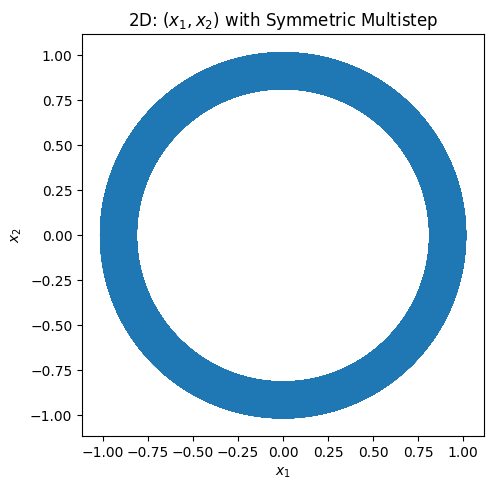

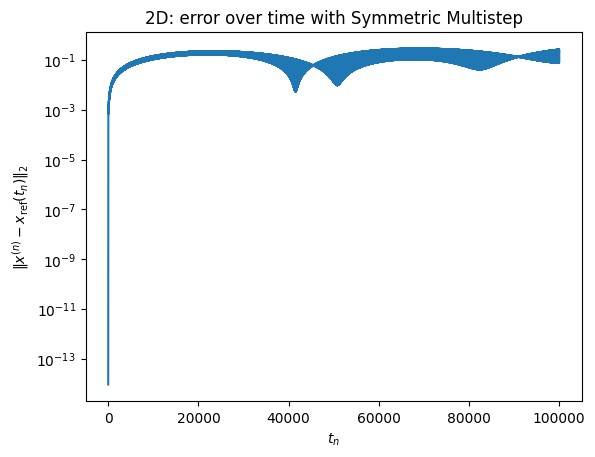

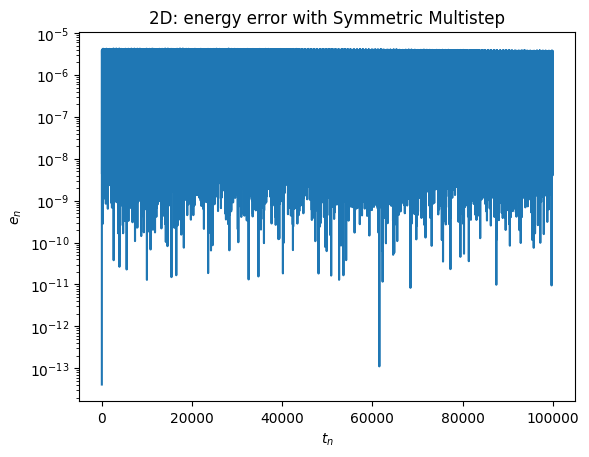

In [2]:
task5A(symmetricMultistep,"2d")

IndexError: index 1 is out of bounds for axis 0 with size 1

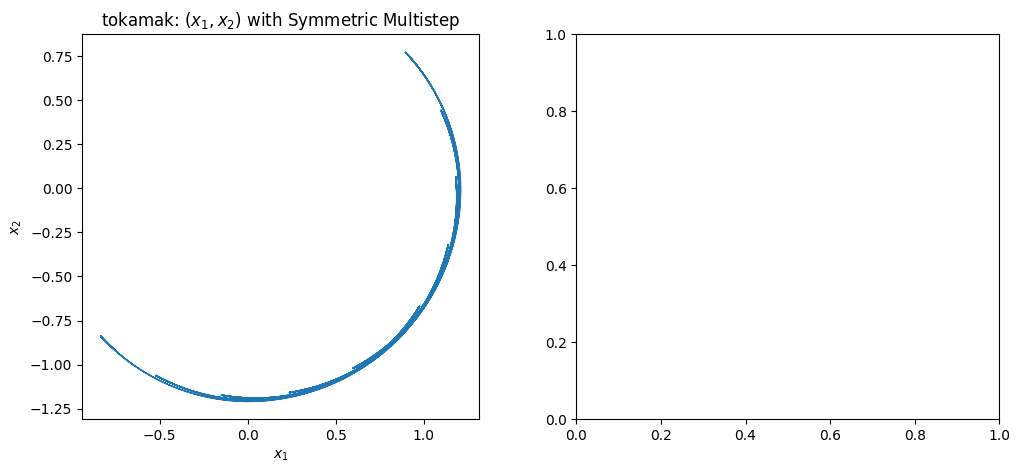

In [ ]:
task5A(symmetricMultistep,"totak")

XRef Done
i = 0 done
i = 1 done
i = 2 done


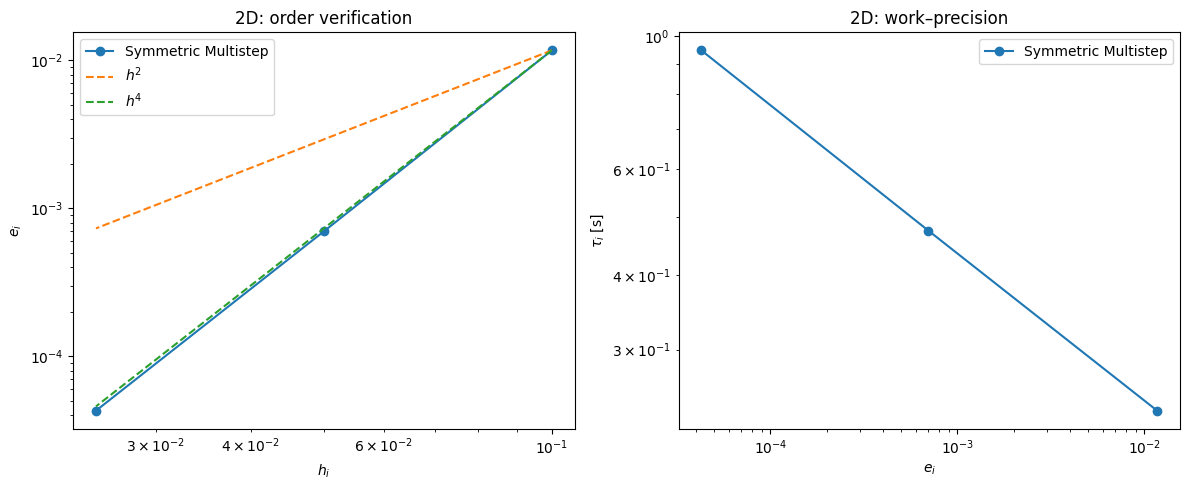

In [4]:
task5B([symmetricMultistep],"2d")

XRef Done
i = 0 done
i = 1 done
i = 2 done


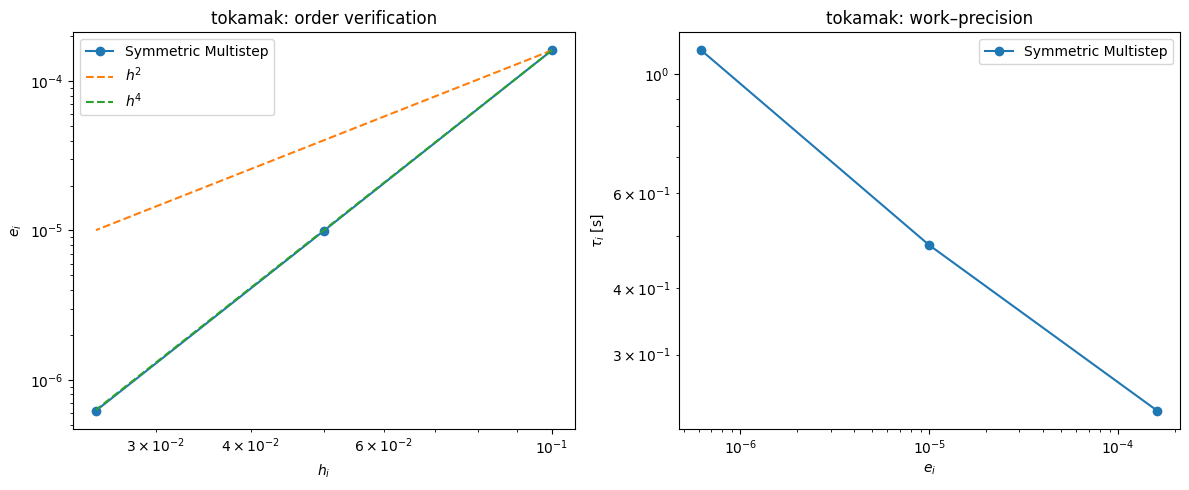

In [5]:
task5B([symmetricMultistep],"totak")

In [6]:
import numpy as np
alpha = np.array([1,-7/5,9/25,22/125,-34/125,22/125,9/25,-7/5,1])


print(np.abs(np.roots(alpha)))

[1. 1. 1. 1. 1. 1. 1. 1.]


first bad index: []


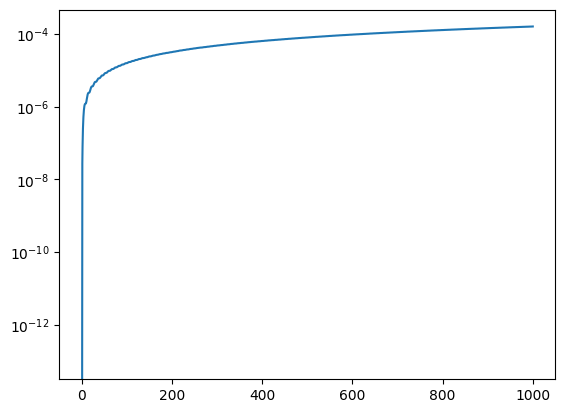

In [7]:
import numpy as np
import matplotlib.pyplot as plt
sysT = create_tokamak()
X, V, t, _ = symmetricMultistep(sysT, 0.1, 1000)

dist = np.linalg.norm(X - X[0], axis=1)
bad = np.where(~np.isfinite(dist) | (dist > 10))[0]
print("first bad index:", bad[:1])

Xref = findXref(sysT, t)
err = np.linalg.norm(X - Xref, axis=1)
plt.semilogy(t, err)

first bad index: []


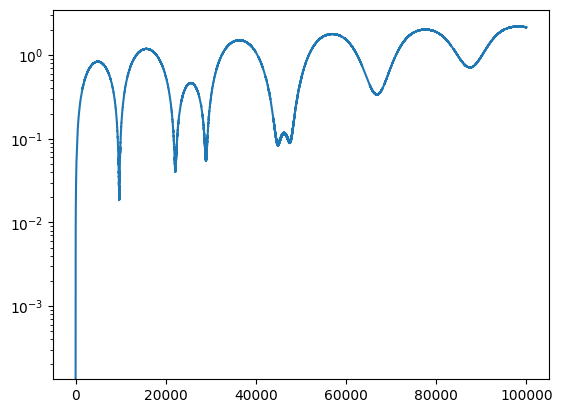

In [8]:
X, V, t, _ = symmetricMultistep(sysT, 0.1, 1e5)
dist = np.linalg.norm(X - X[0], axis=1)
plt.semilogy(t, dist)           # where does it leave the banana orbit?
bad = np.where(~np.isfinite(dist) | (dist > 10))[0]
print("first bad index:", bad[:1])

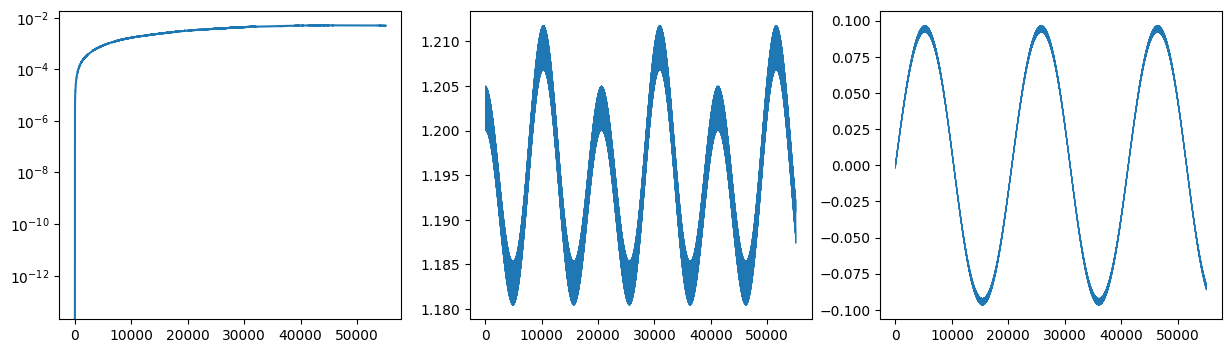

In [9]:
k = 550846
Xref = findXref(sysT, t[:k], rtol=1e-13)
err = np.linalg.norm(X[:k] - Xref, axis=1)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogy(t[:k], err)                                  # error growth
ax[1].plot(t[:k], np.hypot(X[:k,0], X[:k,1]), lw=0.3)       # R(t)
ax[2].plot(t[:k], X[:k,2], lw=0.3)                          # x3(t)

[[-9.52499120e-04 -1.18777258e+00 -8.24599594e-02]
 [-9.46892559e-04 -1.18765373e+00 -8.26346829e-02]
 [-9.41043339e-04 -1.18755003e+00 -8.28187971e-02]
 [-9.35106542e-04 -1.18746223e+00 -8.30109992e-02]
 [-9.29238329e-04 -1.18739094e+00 -8.32099233e-02]
 [-9.23594587e-04 -1.18733669e+00 -8.34141569e-02]]


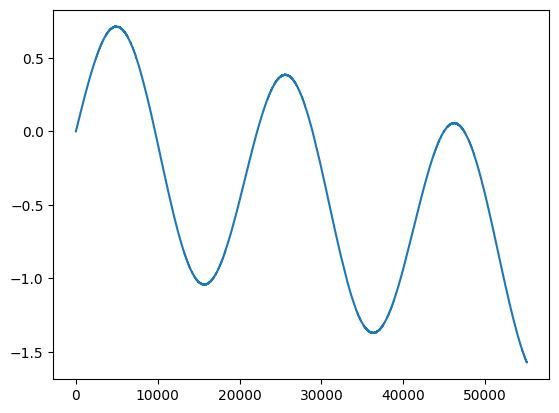

In [10]:
k = 550846
ang = np.arctan2(X[:k,1], X[:k,0])      # toroidal angle
plt.plot(t[:k], ang)
print(X[k-5:k+1])

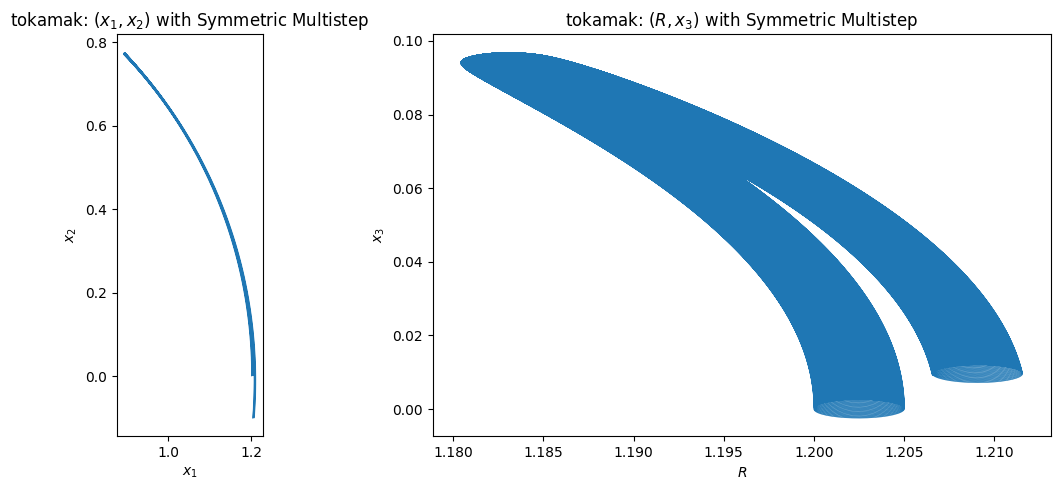

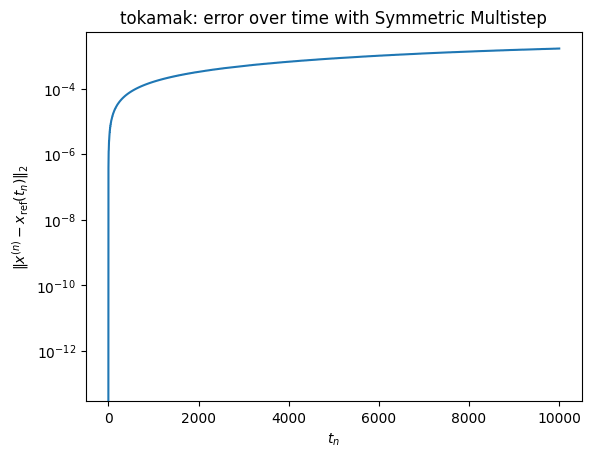

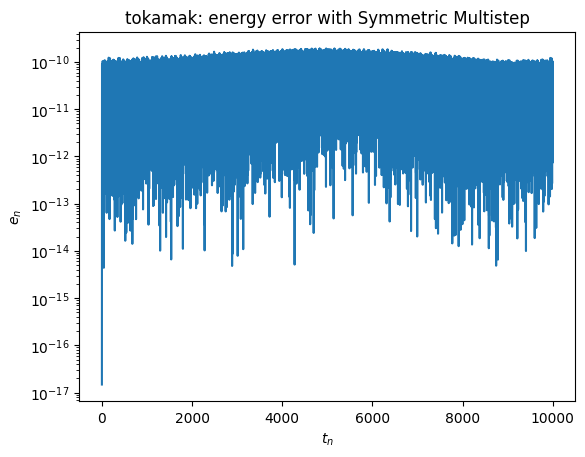

In [5]:
task5A(symmetricMultistep,"tokamak",T=1e4)